# Classifying Fashion-MNIST

Now it's your turn to build and train a neural network. You'll be using the [Fashion-MNIST dataset](https://github.com/zalandoresearch/fashion-mnist), a drop-in replacement for the MNIST dataset. MNIST is actually quite trivial with neural networks where you can easily achieve better than 97% accuracy. Fashion-MNIST is a set of 28x28 greyscale images of clothes. It's more complex than MNIST, so it's a better representation of the actual performance of your network, and a better representation of datasets you'll use in the real world.

<img src='assets/fashion-mnist-sprite.png' width=500px>

In this notebook, you'll build your own neural network. For the most part, you could just copy and paste the code from Part 3, but you wouldn't be learning. It's important for you to write the code yourself and get it to work. Feel free to consult the previous notebooks though as you work through this.

First off, let's load the dataset through torchvision.

In [1]:
import torch
from torchvision import datasets, transforms
import helper

# Define a transform to normalize the data
transform = transforms.Compose([transforms.ToTensor(),
                                transforms.Normalize((0.5,), (0.5,))])
# Download and load the training data
trainset = datasets.FashionMNIST('~/.pytorch/F_MNIST_data/', download=True, train=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)

# Download and load the test data
testset = datasets.FashionMNIST('~/.pytorch/F_MNIST_data/', download=True, train=False, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=64, shuffle=True)

100%|██████████| 26.4M/26.4M [00:02<00:00, 13.1MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 201kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.77MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 18.2MB/s]


Here we can see one of the images.

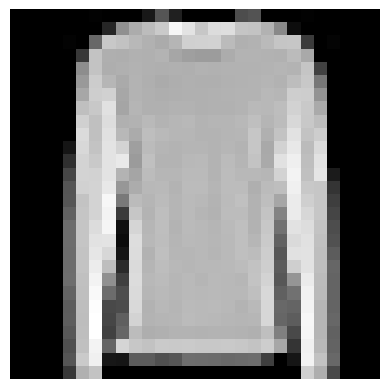

In [4]:
import matplotlib.pyplot as plt

image, label = next(iter(trainloader))
# Convertendo o tensor para o formato de imagem (H, W) removendo dimensões extras
plt.imshow(image[0].squeeze(), cmap='gray')
plt.axis('off')
plt.show()

## Building the network

Here you should define your network. As with MNIST, each image is 28x28 which is a total of 784 pixels, and there are 10 classes. You should include at least one hidden layer. We suggest you use ReLU activations for the layers and to return the logits or log-softmax from the forward pass. It's up to you how many layers you add and the size of those layers.

In [5]:
import torch.nn as nn
import torch.nn.functional as F

class Classifier(nn.Module):
    def __init__(self):
        super().__init__()
        # Camadas lineares (totalmente conectadas)
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, 64)
        self.fc4 = nn.Linear(64, 10)

    def forward(self, x):
        # Certifica-se de que o tensor de entrada seja achatado (flat)
        x = x.view(x.shape[0], -1)

        # Passagem pelas camadas com ativação ReLU
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.relu(self.fc3(x))

        # Saída com Log-Softmax
        x = F.log_softmax(self.fc4(x), dim=1)

        return x

# Train the network

Now you should create your network and train it. First you'll want to define [the criterion](http://pytorch.org/docs/master/nn.html#loss-functions) ( something like `nn.CrossEntropyLoss`) and [the optimizer](http://pytorch.org/docs/master/optim.html) (typically `optim.SGD` or `optim.Adam`).

Then write the training code. Remember the training pass is a fairly straightforward process:

* Make a forward pass through the network to get the logits
* Use the logits to calculate the loss
* Perform a backward pass through the network with `loss.backward()` to calculate the gradients
* Take a step with the optimizer to update the weights

By adjusting the hyperparameters (hidden units, learning rate, etc), you should be able to get the training loss below 0.4.

In [6]:
from torch import optim

# Criando o modelo
model = Classifier()

# Definindo o critério (NLLLoss porque usamos Log-Softmax na saída) e o otimizador
criterion = nn.NLLLoss()
optimizer = optim.Adam(model.parameters(), lr=0.003)

In [7]:
epochs = 5

for e in range(epochs):
    running_loss = 0
    for images, labels in trainloader:
        # Redimensionando as imagens para um vetor unidimensional de 784 elementos
        images = images.view(images.shape[0], -1)

        # Zerando os gradientes acumulados
        optimizer.zero_grad()

        # Passagem para a frente (forward pass)
        output = model(images)

        # Cálculo da perda
        loss = criterion(output, labels)

        # Passagem para trás (backward pass)
        loss.backward()

        # Atualização dos pesos
        optimizer.step()

        running_loss += loss.item()
    else:
        print(f"Epoch {e+1}/{epochs} - Training loss: {running_loss/len(trainloader):.4f}")

Epoch 1/5 - Training loss: 0.5166
Epoch 2/5 - Training loss: 0.3927
Epoch 3/5 - Training loss: 0.3549
Epoch 4/5 - Training loss: 0.3353
Epoch 5/5 - Training loss: 0.3193


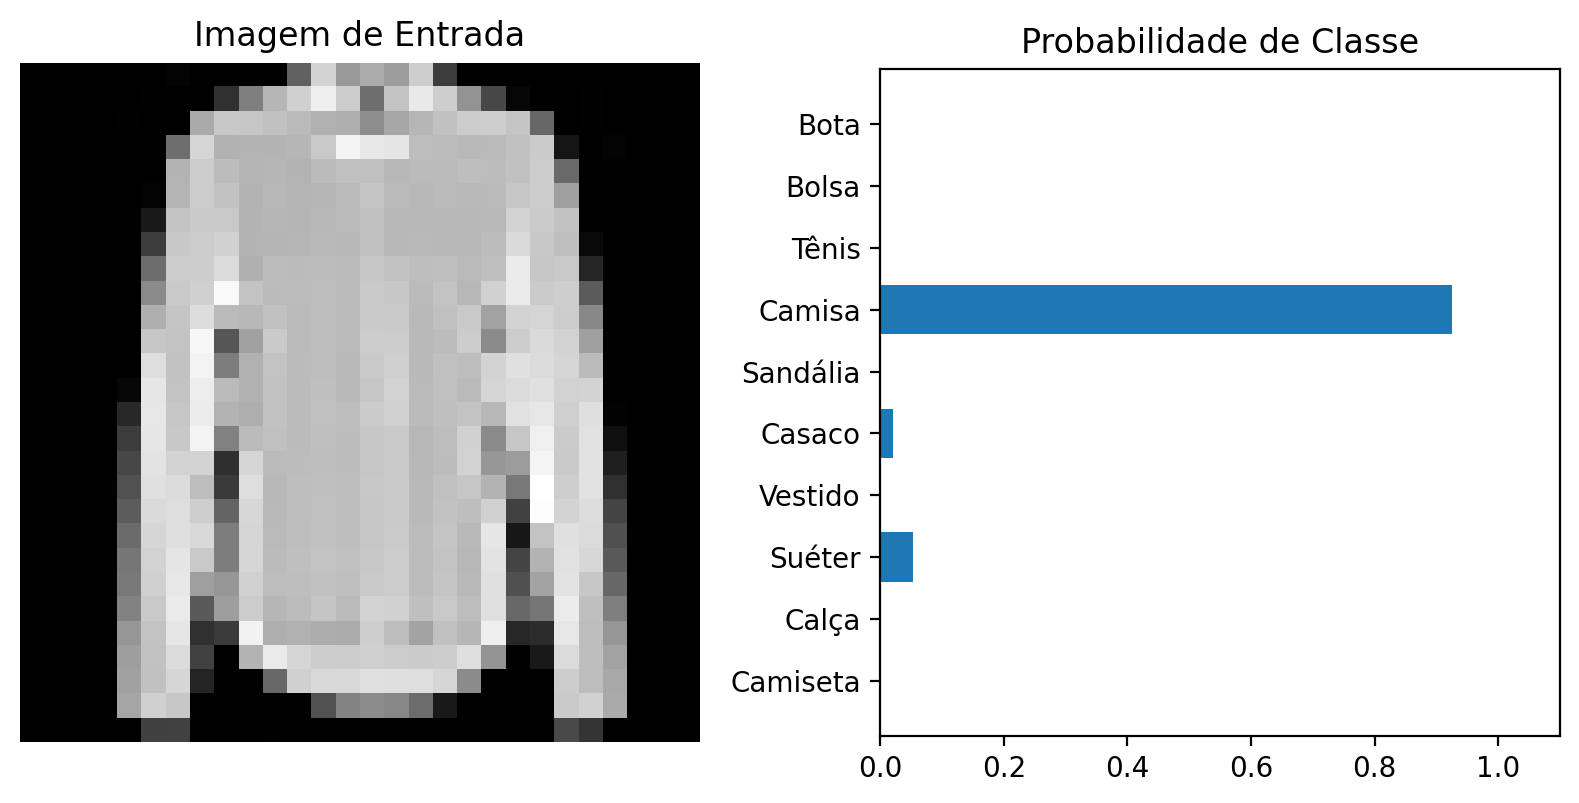

In [18]:
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import torch
import matplotlib.pyplot as plt
import numpy as np

# Obtendo uma imagem de teste
dataiter = iter(testloader)
images, labels = next(dataiter)
img = images[0]

# Convertendo a imagem 2D em vetor 1D de tamanho 784
img_input = img.view(1, 784)

# Desativando o cálculo de gradientes para inferência
with torch.no_grad():
    logps = model(img_input)

# Calculando as probabilidades aplicando exponencial no log-softmax
ps = torch.exp(logps)

# Convertendo os tensores para arrays do numpy para visualização
img = img.squeeze().numpy()
ps = ps.data.numpy().squeeze()

# Nomes das classes do Fashion-MNIST
classes = ['Camiseta', 'Calça', 'Suéter', 'Vestido', 'Casaco',
           'Sandália', 'Camisa', 'Tênis', 'Bolsa', 'Bota']

# Plotando a imagem e as probabilidades lado a lado
fig, (ax1, ax2) = plt.subplots(figsize=(6,9), cols=2) if 'cols' in dir() else plt.subplots(figsize=(8, 4), ncols=2)

ax1.imshow(img, cmap='gray')
ax1.axis('off')
ax1.set_title('Imagem de Entrada')

ax2.barh(np.arange(10), ps)
ax2.set_aspect(0.1)
ax2.set_yticks(np.arange(10))
ax2.set_yticklabels(classes)
ax2.set_title('Probabilidade de Classe')
ax2.set_xlim(0, 1.1)

plt.tight_layout()
plt.show()